# Function 3 - Week 5: Model Predictions

#### Model Predictions using Official Observations up to and including Week 4 return, received on **23 October 2026**.

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "model_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review
from model_review_helpers import (
    make_regression_models, fit_model_review, review_latest_predictions,
    build_review_candidates, score_review_candidates,
    query_prediction, weight_sensitivity,
)
from model_review_plots import plot_held_out_comparison, plot_latest_predictions
from coverage_cache import compare_coverage_batches
from query_budget import remaining_queries
from plot_helpers import PLOT_CONFIG
from three_input_model_helpers import save_three_input_model_views, save_three_input_query_views

In [2]:
# Settings for this run. Keep model assumptions and search settings here.
FUNCTION_NUMBER = 3
CURRENT_WEEK = 5
INPUT_COLUMNS = ["x1", "x2", "x3"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 15, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"
PORTAL_DECIMALS = 6
GP_NAMES = ["Gaussian process", "GP: separate length scales"]
# Retain the existing GP diagonal regularisation; it is not a measured noise level.
MODEL_SETTINGS = dict(
    noise_fraction=0.10, ridge_alpha=1.0,
    kernel_ridge_alpha=0.1, kernel_ridge_gamma=1.0,
    polynomial_degree=2, polynomial_ridge_alpha=1.0,
    length_scale=0.3, length_scale_bounds=(0.03, 2.0),
    amplitude=1.0, amplitude_bounds=(0.01, 100.0), optimiser_restarts=3, seed=42,
)
EXPLORATION_WEIGHT = 1.96
SEARCH_SETTINGS = dict(
    broad_power=14, broad_seed=42, local_power=12, local_seed=43,
    local_radius=0.15, precision=PORTAL_DECIMALS, include_corners=True,
)
COVERAGE_SETTINGS = dict(
    max_queries=1, optimization_power=12, evaluation_power=15,
    optimization_seed=42, evaluation_seed=43, comparison_seed=42, verbose=False,
)
EXPLORATION_WEIGHTS = (0.0, 1.0, 1.96, 3.0)
VALIDATION_MODELS = ["Ridge", "Quadratic ridge"]
REFERENCE_MODEL = "Kernel ridge"
VIEW_SETTINGS = dict(grid_side=61, slice_values=(0.10, 0.25, 0.40, 0.50, 0.60, 0.75, 0.90))
QUERY_GRID_SIDE = 61
VALIDATION_SIZE = (15, 5)
LATEST_RESULT_SIZE = (11, 5.5)

In [3]:
# Validate the same snapshot used by the exploration review.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
inputs = review["inputs"].to_numpy(dtype=float)
raw_y = review["outputs"].to_numpy(dtype=float)
anchor = inputs[int(np.argmax(raw_y))].copy()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))

,observation_id,source_round,x1,x2,x3,y,output_rank
18,round-04,4,0.903842,0.268903,0.8752,-0.056642,8


In [4]:
# Fit each complete estimator within every held-out fold.
models = make_regression_models(len(INPUT_COLUMNS), **MODEL_SETTINGS)
model_run = fit_model_review(models, inputs, raw_y, gp_names=GP_NAMES)
selected_model = model_run["selected_model"]
modelled_axes = tuple(range(len(INPUT_COLUMNS)))
display(model_run["table"].round(6))
display(pd.Series({"Selected GP": model_run["selected_name"], "Fitted kernel": model_run["fitted_kernel"]}))

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 0.03. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better v

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better v

C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified upper bound 2.0. Increasing the bound and calling fit again may find a better v

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,GP: separate length scales,0.002700,0.037542,0.075703,0.779327,7.859790
1,Mean baseline,0.045637,0.048173,0.082160,1.000000,0.000000
2,Ridge,0.044663,0.053200,0.085620,1.104350,-4.210962
3,Gaussian process,0.000800,0.055242,0.085635,1.146756,-4.229296
4,Kernel ridge,0.035414,0.066567,0.094543,1.381838,-15.070607
5,Linear regression,0.048858,0.065211,0.095242,1.353689,-15.922192
6,Quadratic ridge,0.044252,0.079598,0.110504,1.652342,-34.498011


Selected GP                      GP: separate length scales
Fitted kernel    1.19**2 * RBF(length_scale=[2, 2, 0.0608])
dtype: str

,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,GP: separate length scales,-0.0338,0.0229,40.3456,0.4796,0.0776
1,Kernel ridge,-0.0937,-0.0371,65.4518,0.8093,0.0967
2,Mean baseline,-0.0983,-0.0417,73.5484,1.3531,0.0838
3,Gaussian process,-0.1004,-0.0438,77.3255,1.3768,0.0874
4,Ridge,-0.1231,-0.0665,117.3187,3.1704,0.0866
5,Quadratic ridge,-0.1277,-0.0711,125.4476,2.1762,0.1123
6,Linear regression,-0.1424,-0.0857,151.3789,4.2658,0.0957


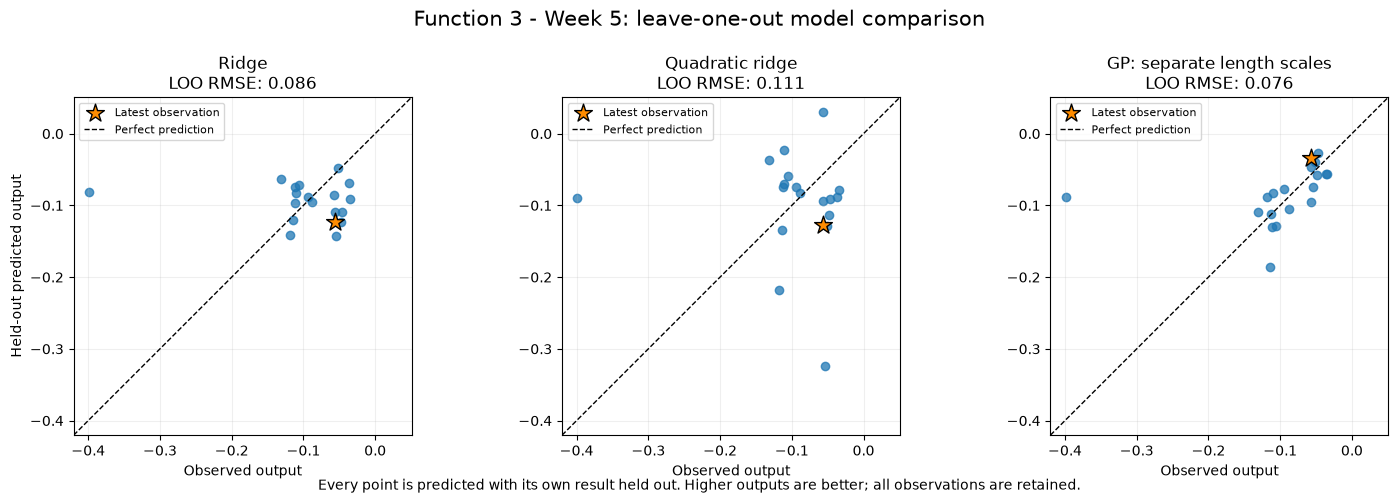

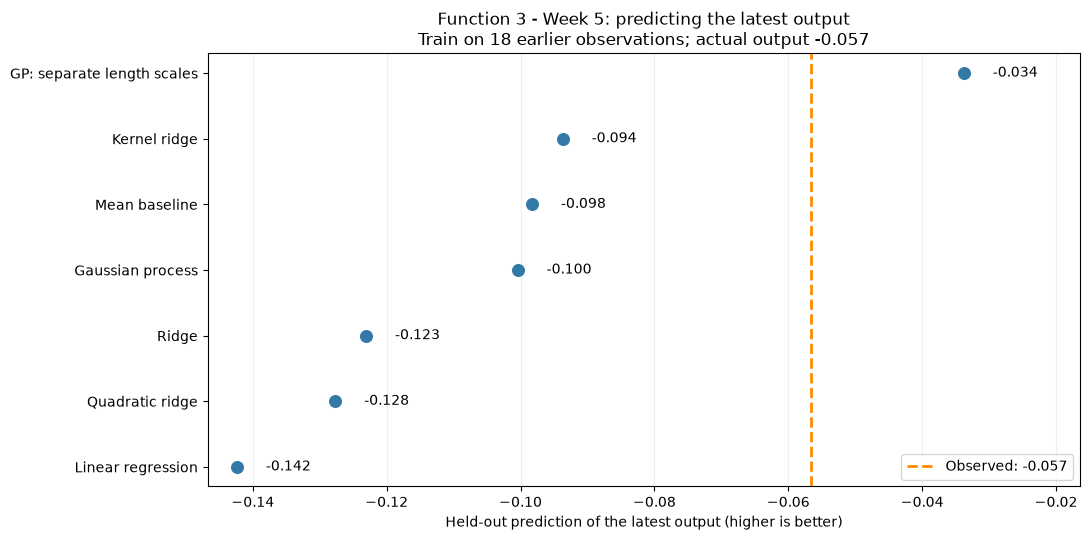

In [5]:
# This checks the latest held-out result retrospectively; it is not a saved forecast.
latest_review = review_latest_predictions(model_run["predictions"], raw_y, review["latest_mask"])
latest_output = float(raw_y[review["latest_mask"]][0])
display(latest_review.round(4))
display(plot_held_out_comparison(
    model_run["predictions"], raw_y,
    model_names=[*VALIDATION_MODELS, model_run["selected_name"]], latest_mask=review["latest_mask"],
    title=f"{TITLE}: leave-one-out model comparison", figsize=VALIDATION_SIZE,
    save_to=FIGURES_DIR / "model-comparison-validation.png",
))
display(plot_latest_predictions(
    latest_review, latest_output, n_training_rows=int((~review["latest_mask"]).sum()),
    title=f"{TITLE}: predicting the latest output", figsize=LATEST_RESULT_SIZE,
    save_to=FIGURES_DIR / "latest-output-predictions.png",
))

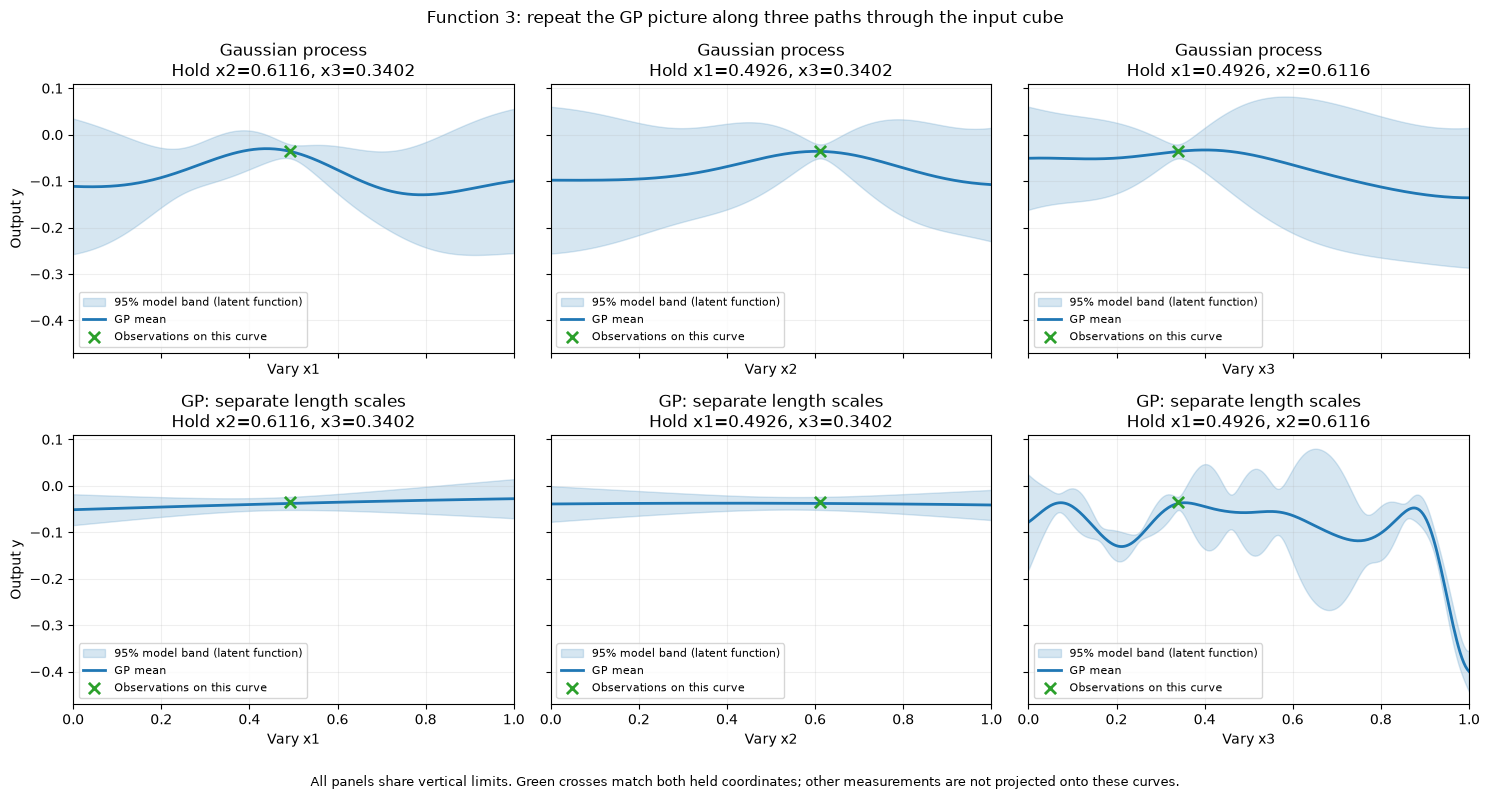

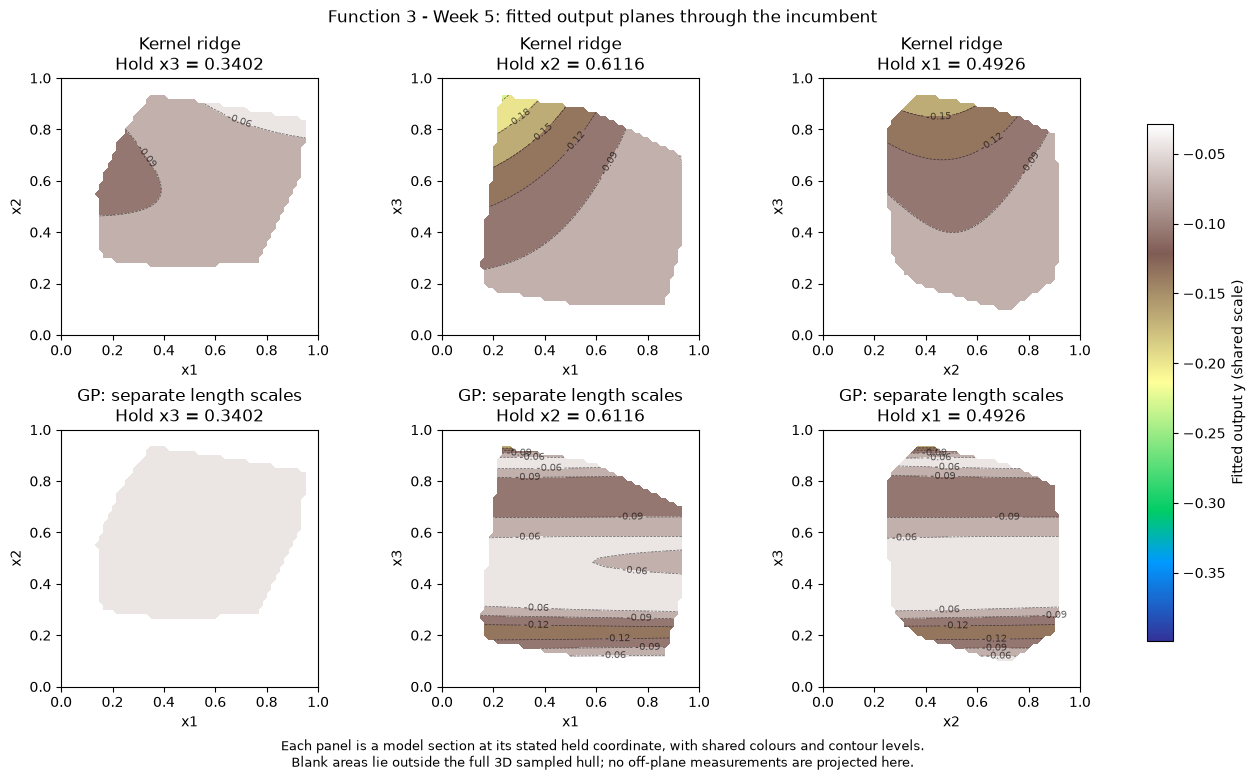

In [6]:
# Three-input renderers hold the omitted coordinate fixed and test the full 3D hull.
views = save_three_input_model_views(
    model_run, inputs, raw_y, gp_names=GP_NAMES, title=TITLE, figures_dir=FIGURES_DIR,
    reference_label=REFERENCE_MODEL, **VIEW_SETTINGS,
)
display(*views["figures"])
views["terrain"].show(config=PLOT_CONFIG)

In [7]:
# Reuse the geometric coverage cache, then score the exact rounded candidate inputs.
coverage = compare_coverage_batches(
    existing=inputs, cache_dir=ANALYSIS_DIR / ".coverage-cache", **COVERAGE_SETTINGS,
)
candidates = build_review_candidates(
    inputs, anchor, coverage["proposed_batches"][1], input_columns=INPUT_COLUMNS, **SEARCH_SETTINGS,
)
scored = score_review_candidates(
    selected_model, candidates, input_columns=INPUT_COLUMNS,
    weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
by_source = scored.loc[scored.groupby("candidate_source")["ucb"].idxmax()].sort_values("ucb", ascending=False)
display(by_source.round(6))
display(pd.DataFrame(coverage["results"]))

,x1,x2,x3,posterior_mean,posterior_sd,ucb,candidate_source
0,0.019633,0.050082,0.647040,-0.086909,0.085961,0.081575,Full input space
1604,0.640985,0.735676,0.402523,-0.044536,0.049074,0.051648,Near incumbent
6569,0.061429,0.217144,0.094472,-0.045383,0.030069,0.013551,Single coverage query


,q,max_distance,p95_distance
0,0,0.463653,0.359026
1,1,0.463653,0.356769


In [8]:
# Every coordinate remains free in the rounded candidate comparison.
recommended = scored.iloc[0]
next_query = recommended[INPUT_COLUMNS].to_numpy(dtype=float)
proposal = query_prediction(
    selected_model, next_query, inputs, raw_y, weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
proposal_source = recommended.candidate_source
display(pd.Series(proposal))

point                         [0.019633, 0.050082, 0.64704]
predicted_output                                  -0.086909
posterior_std                                      0.085961
ucb                                                0.081575
predicted_mean_improvement                        -0.052074
inside_sampled_hull                                   False
portal_input                     0.019633-0.050082-0.647040
dtype: object

In [9]:
# Reuse the same candidate pool and predictions while changing the exploration weight.
exploration_sensitivity = weight_sensitivity(
    scored, inputs, input_columns=INPUT_COLUMNS, modelled_axes=modelled_axes,
    weights=EXPLORATION_WEIGHTS, precision=PORTAL_DECIMALS,
)
display(exploration_sensitivity.round(6))

,Weight,x1,x2,x3,Predicted output,Posterior SD
0,0.00,0.991458,0.580959,0.352394,-0.027779,0.024054
1,1.00,0.995320,0.948612,0.394807,-0.040767,0.052329
2,1.96,0.019633,0.050082,0.647040,-0.086909,0.085961
3,3.00,0.019633,0.050082,0.647040,-0.086909,0.085961


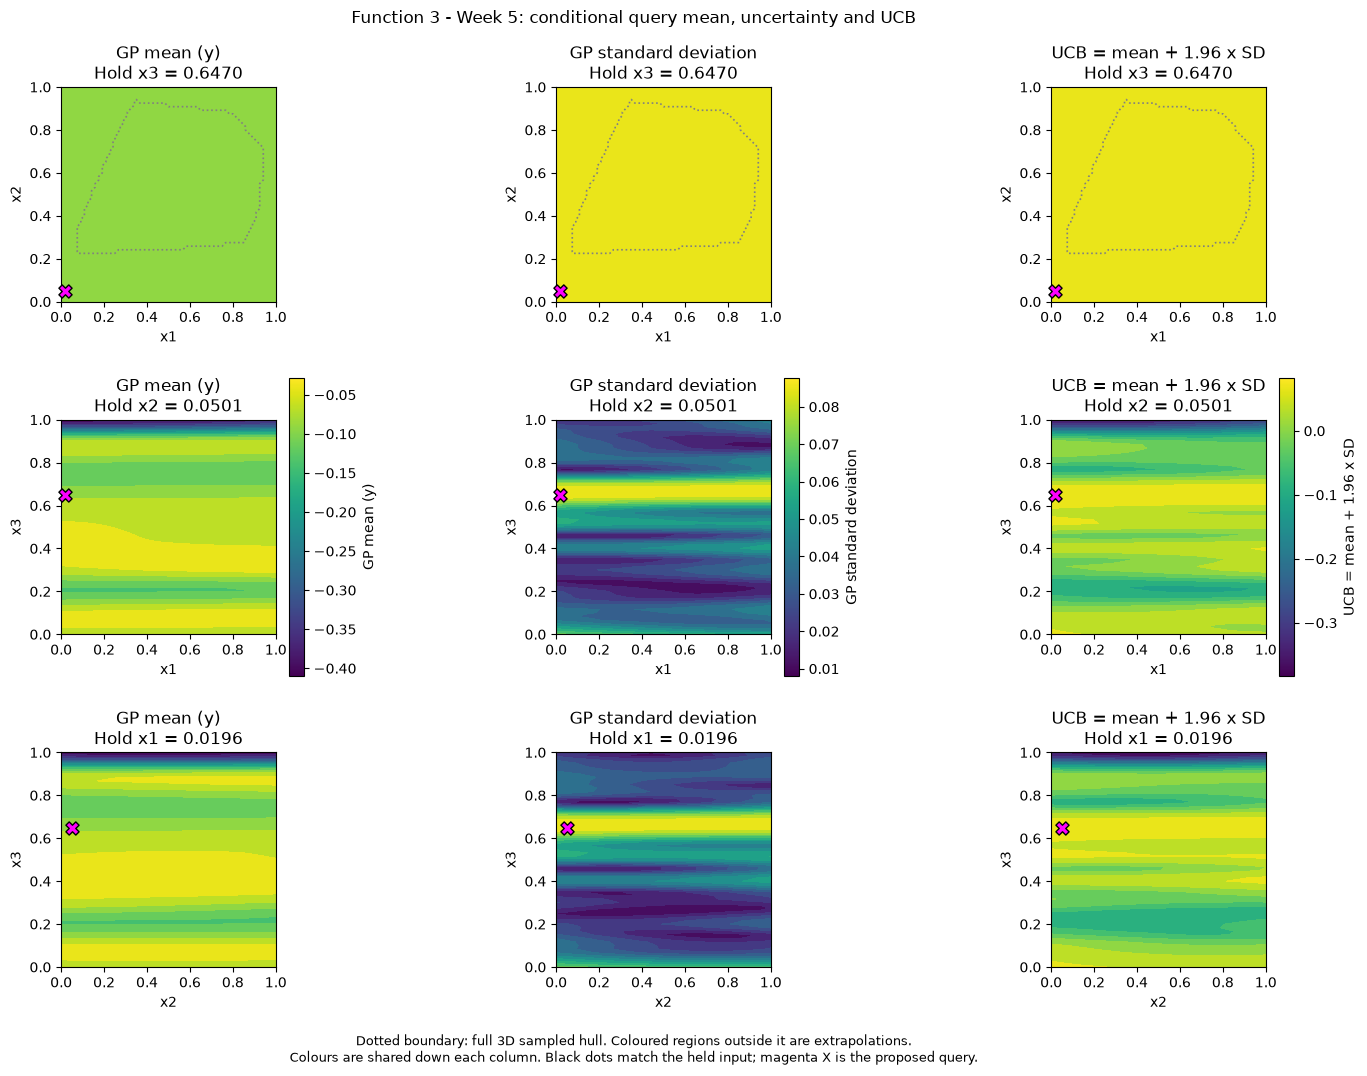

In [10]:
# The proposal cloud has input axes; score planes pass through the proposal itself.
query_views = save_three_input_query_views(
    selected_model, inputs, raw_y, anchor, next_query, title=TITLE, figures_dir=FIGURES_DIR,
    weight=EXPLORATION_WEIGHT, grid_side=QUERY_GRID_SIDE,
)
query_views["cloud"].show(config=PLOT_CONFIG)
display(query_views["scores"])

In [11]:
# Preserve the saved summary contract read by the separate cohort comparison.
analysis_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(raw_y),
    "query_model": model_run["selected_name"], "proposal_status": "proposed_not_submitted",
    "portal_input": proposal["portal_input"], "point": proposal["point"],
    "predicted_output": proposal["predicted_output"], "posterior_std": proposal["posterior_std"],
    "ucb_weight": EXPLORATION_WEIGHT, "candidate_source": proposal_source,
    "candidate_count": len(scored),
    "inside_sampled_hull": proposal["inside_sampled_hull"], "best_observed_output": float(raw_y.max()),
    "gp_rmse": model_run["selected_rmse"], "baseline_rmse": model_run["baseline_rmse"],
    "gp_baseline_rmse_ratio": model_run["selected_rmse"] / model_run["baseline_rmse"],
    "lowest_rmse_model": model_run["table"].iloc[0]["Model"],
    "distinct_weight_choices": len(exploration_sensitivity[INPUT_COLUMNS].drop_duplicates()),
    "remaining_queries": remaining_queries(WEEK_DIR),
    "model_comparison": model_run["table"].to_dict(orient="records"),
    "fitted_kernel": model_run["fitted_kernel"],
    "length_scales": np.atleast_1d(selected_model.kernel_.k2.length_scale).tolist(),
    "weight_sensitivity": exploration_sensitivity.to_dict(orient="records"),
}
print(json.dumps(analysis_summary, indent=2))

{
  "function": 3,
  "week": 5,
  "observations": 19,
  "query_model": "GP: separate length scales",
  "proposal_status": "proposed_not_submitted",
  "portal_input": "0.019633-0.050082-0.647040",
  "point": [
    0.019633,
    0.050082,
    0.64704
  ],
  "predicted_output": -0.08690945470370987,
  "posterior_std": 0.08596127663192338,
  "ucb_weight": 1.96,
  "candidate_source": "Full input space",
  "candidate_count": 20497,
  "inside_sampled_hull": false,
  "best_observed_output": -0.034835313350078584,
  "gp_rmse": 0.07570284931593903,
  "baseline_rmse": 0.08216049100123747,
  "gp_baseline_rmse_ratio": 0.9214021045078566,
  "lowest_rmse_model": "GP: separate length scales",
  "distinct_weight_choices": 3,
  "remaining_queries": 9,
  "model_comparison": [
    {
      "Model": "GP: separate length scales",
      "Training MAE": 0.0027002913399973945,
      "LOO MAE": 0.037542299465464876,
      "LOO RMSE": 0.07570284931593903,
      "MAE / baseline": 0.779326760959285,
      "RMSE red